# 7. Transfer Learning for CNNs

In this notebook we load a small datasets that contains pictures of dolphins and elephants. We classify the images using CNNs and compare two approaches to see what works better:
1. Training a CNN from scratch.
2. Finetuning a pretrained ResNet.

In [1]:
import torch
from torchvision import transforms
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets

torch.manual_seed(0)

Let's load our data and have a look at the shape of some images:

In [2]:
dataset = datasets.ImageFolder(root='./data/animals')
for i, data in enumerate(dataset):
    print(data)
    if i == 5:
        break

(<PIL.Image.Image image mode=RGB size=300x179 at 0x108B366F0>, 0)
(<PIL.Image.Image image mode=RGB size=300x179 at 0x175E74080>, 0)
(<PIL.Image.Image image mode=RGB size=300x166 at 0x108B366F0>, 0)
(<PIL.Image.Image image mode=RGB size=300x259 at 0x13F93AF90>, 0)
(<PIL.Image.Image image mode=RGB size=300x225 at 0x17649BE90>, 0)
(<PIL.Image.Image image mode=RGB size=300x277 at 0x175E74080>, 0)


We see that the pictures have all `width=300` but a varying height. To use them in transfer learning they need to have the standard shape of size `(224, 224)`, which is the data format of ImageNet (on which most pretrained models are trained on).  

To get them into this shape, we first define a transformation that increases the image height to 224 (this will also increase the width) and then take the 224 pixel center square of the picture:

In [3]:
image_transforms = transforms.Compose([
             transforms.Resize(size=224),
             transforms.CenterCrop(size=224),
             transforms.ToTensor(),
             transforms.Normalize([0.485, 0.456, 0.406],[0.229, 0.224, 0.225]) # standard normalization for transfer learning
    ])

With this transformation, we now load all images from the disk.

Next, we split the data into train and test and define the data loaders that loads the data from disk.

In [4]:
data = datasets.ImageFolder(root='./data/animals', transform=image_transforms)
train_set, test_set = torch.utils.data.random_split(data, [100, 29])

batch_size = 10

trainloader = torch.utils.data.DataLoader(train_set, batch_size=batch_size,
                                          shuffle=True)
testloader = torch.utils.data.DataLoader(test_set, batch_size=29,
                                         shuffle=False)

## Tasks:
### Task 1.
Train a CNN from scratch to identify the object on the image (dolphin or elephant). For this, use the same CNN architecture as in Task 1 of the notebook from last week. To make this work, here are a few things you need to change:
1. You need to change the input size of the fully-connected layer to match the new image dimension.
2. You need to change the output dimension of the fully-connected layer to classify only two classes instead of ten.

Used the dataloader to load the data (see cell above), which allows us to train our model in mini-batches (aka "mini-batch gradient descent"). We already did this last week, so you can check there how this works. 

Train for 20 epochs on the train data and afterwards compute the accuracy on the test data.

In [5]:
import torch.nn as nn
import torch.nn.functional as F


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
        self.fc1 = nn.Linear(16 * 53 * 53, 120)  # neue Bildgröße -> 44944 Eingänge
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 2)              # 2 Klassen: Delfin / Elefant

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1) # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


net = Net()

In [6]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

In [7]:
losses_cnn = []

for epoch in range(20):
    running_loss = 0.0
    for inputs, labels in trainloader:
        optimizer.zero_grad()
        loss = criterion(net(inputs), labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    epoch_loss = running_loss / len(trainloader)   # Durchschnitt pro Batch
    losses_cnn.append(epoch_loss)                  # merken
    print(f'Epoche {epoch + 1}: loss {epoch_loss:.3f}')

Epoche 1: loss 0.691
Epoche 2: loss 0.677
Epoche 3: loss 0.654
Epoche 4: loss 0.605
Epoche 5: loss 0.513
Epoche 6: loss 0.387
Epoche 7: loss 0.287
Epoche 8: loss 0.201
Epoche 9: loss 0.184
Epoche 10: loss 0.191
Epoche 11: loss 0.211
Epoche 12: loss 0.154
Epoche 13: loss 0.076
Epoche 14: loss 0.057
Epoche 15: loss 0.028
Epoche 16: loss 0.020
Epoche 17: loss 0.014
Epoche 18: loss 0.012
Epoche 19: loss 0.009
Epoche 20: loss 0.008


In [8]:
def evaluate(net, loader):
    net.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            predicted = net(images).argmax(dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    net.train()
    return correct / total


print(f'Test accuracy: {evaluate(net, testloader):.1%}')

Test accuracy: 86.2%


### Task 2:
Instead of training a CNN from scratch, we now want to load a pretrained **ResNet18** model and re-train its last layer to do our classifcation task.
PyTorch has a [tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html#convnet-as-fixed-feature-extractor) on transfer learning, which you can check to see how this works (note: its enough to read the section `ConvNet as fixed feature extractor`).

Train the last layer of the pre-trained RestNet model for 20 epochs and compare the results to task 1.

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [10]:
model_conv = torchvision.models.resnet18(weights='IMAGENET1K_V1')
for param in model_conv.parameters():
    param.requires_grad = False

# Parameters of newly constructed modules have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)

model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that only parameters of final layer are being optimized as
# opposed to before.
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)

In [11]:
losses_transfer = []

for epoch in range(20):
    running_loss = 0.0
    for inputs, labels in trainloader:
        optimizer_conv.zero_grad()
        loss = criterion(model_conv(inputs), labels)
        loss.backward()
        optimizer_conv.step()
        running_loss += loss.item()
    epoch_loss = running_loss / len(trainloader)   # Durchschnitt pro Batch
    losses_transfer.append(epoch_loss)                  # merken
    print(f'Epoche {epoch + 1}: loss {epoch_loss:.3f}')

Epoche 1: loss 0.664
Epoche 2: loss 0.442
Epoche 3: loss 0.200
Epoche 4: loss 0.157
Epoche 5: loss 0.104
Epoche 6: loss 0.094
Epoche 7: loss 0.143
Epoche 8: loss 0.220
Epoche 9: loss 0.118
Epoche 10: loss 0.100
Epoche 11: loss 0.116
Epoche 12: loss 0.083
Epoche 13: loss 0.099
Epoche 14: loss 0.101
Epoche 15: loss 0.063
Epoche 16: loss 0.052
Epoche 17: loss 0.071
Epoche 18: loss 0.104
Epoche 19: loss 0.059
Epoche 20: loss 0.036


In [12]:
print(f'Test accuracy: {evaluate(model_conv, testloader):.1%}')

Test accuracy: 100.0%


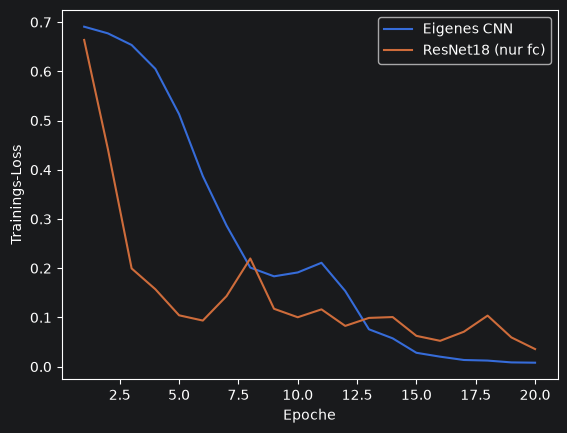

In [13]:
import matplotlib.pyplot as plt

plt.plot(range(1, 21), losses_cnn, label="Eigenes CNN")
plt.plot(range(1, 21), losses_transfer, label="ResNet18 (nur fc)")
plt.xlabel("Epoche")
plt.ylabel("Trainings-Loss")
plt.legend()
plt.show()

### Bonus Task: Object Detection with YOLOv5

Instead of classifying the entire image, we now want to **detect and locate** objects in the images using a pretrained YOLOv5 model.

First, install the `ultralytics` package: `!pip install ultralytics seaborn -q`

1. Load the pretrained YOLOv5s model using `torch.hub.load('ultralytics/yolov5', 'yolov5s', pretrained=True)`.
2. Run inference on 5 **elephant** images from the `./data/animals` folder. (Note: YOLOv5 is trained on the COCO dataset which includes "elephant" but not "dolphin".)
3. Display the results using the model's built-in `.show()` or `.render()` method.
4. Look at the detected classes and bounding boxes — does YOLOv5 detect the elephants correctly?
5. Compare: What is the difference between the **classification** task from Tasks 1–2 and the **object detection** task here?

In [15]:
model_yolo = torch.hub.load('ultralytics/yolov5', 'yolov5s', pretrained=True)

YOLOv5 🚀 2026-11-2 Python-3.12.9 torch-2.14.1 CPU

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


Using cache found in /Users/jun/.cache/torch/hub/ultralytics_yolov5_master
